<a href="https://colab.research.google.com/github/Lathika-M732/24ADI006_DL_EX_8/blob/main/EX_8_DL_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **GENERATION OF SYNTHETIC IMAGES USING A GENERATIVE ADVERSARIAL NETWORK (GAN)**

# Name : Lathika M
# Roll No : 24BAD062

# PART A: DATASET PREPARATION

Name: Lathika M
Register Number: 24BAD062
Experiment: GAN - Dataset Preparation
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)


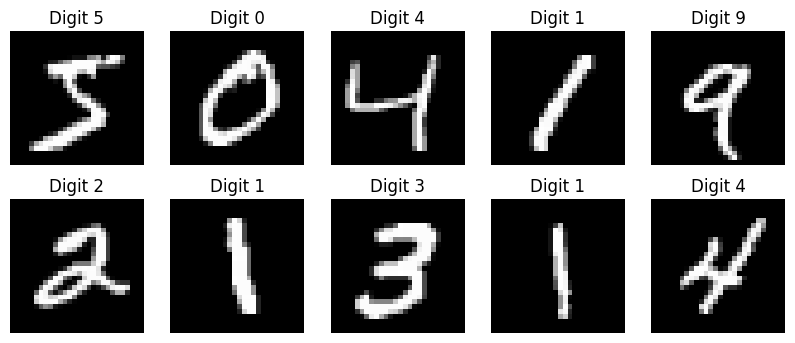

Normalized Data Shape: (60000, 28, 28, 1)
Minimum Pixel Value: -1.0
Maximum Pixel Value: 1.0
Dataset Preparation Completed Successfully
Batch Size: 128


In [3]:
# EXPT NO: 8
# NAME: Lathika M
# REGISTER NO: 24BAD062
# PART A: DATASET PREPARATION

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Name: Lathika M")
print("Register Number: 24BAD062")
print("Experiment: GAN - Dataset Preparation")

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title("Digit " + str(y_train[i]))
    plt.axis('off')

plt.show()

# Normalize pixel values between -1 and 1
X_train = (X_train.astype('float32') - 127.5) / 127.5

# Reshape images
X_train = X_train.reshape(-1, 28, 28, 1)

print("Normalized Data Shape:", X_train.shape)
print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

# Prepare batches
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(
    X_train
).shuffle(60000).batch(BATCH_SIZE, drop_remainder=True)

print("Dataset Preparation Completed Successfully")
print("Batch Size:", BATCH_SIZE)

# PART B: Implementing the Generator and Discriminator

In [4]:
# EXPT NO: 8
# NAME: Lathika M
# REGISTER NO: 24BAD062
# PART B: GENERATOR AND DISCRIMINATOR

import tensorflow as tf
from tensorflow.keras import layers

print("Name: Lathika M")
print("Register Number: 24BAD062")
print("Implementing Generator and Discriminator")

# Random noise dimension
LATENT_DIM = 100

# Generator Model
def build_generator():

    model = tf.keras.Sequential([
        layers.Input(shape=(LATENT_DIM,)),

        layers.Dense(7 * 7 * 128),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Reshape((7, 7, 128)),

        layers.Conv2DTranspose(
            64, kernel_size=4, strides=2,
            padding='same'
        ),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Conv2DTranspose(
            32, kernel_size=4, strides=2,
            padding='same'
        ),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Conv2D(
            1, kernel_size=3,
            padding='same', activation='tanh'
        )
    ])

    return model


# Discriminator Model
def build_discriminator():

    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(
            64, kernel_size=3, strides=2,
            padding='same'
        ),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Conv2D(
            128, kernel_size=3, strides=2,
            padding='same'
        ),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Flatten(),

        layers.Dense(1)
    ])

    return model


# Create models
generator = build_generator()
discriminator = build_discriminator()

print("\nGENERATOR MODEL SUMMARY")
generator.summary()

print("\nDISCRIMINATOR MODEL SUMMARY")
discriminator.summary()

# Generate a sample image
noise = tf.random.normal([1, LATENT_DIM])
generated_image = generator(noise)

print("Generated Image Shape:", generated_image.shape)
print("Generator and Discriminator Created Successfully")

Name: Lathika M
Register Number: 24BAD062
Implementing Generator and Discriminator

GENERATOR MODEL SUMMARY


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 797,697 (3.04 MB)

 Trainable params: 797,697 (3.04 MB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 80,769 (315.50 KB)

 Trainable params: 80,769 (315.50 KB)

 Non-trainable params: 0 (0.00 B)

Generated Image Shape: (1, 28, 28, 1)
Generator and Discriminator Created Successfully


# PART C: GAN TRAINING AND PERFORMANCE MONITORING

Name: Lathika M
Register Number: 24BAD062
GAN Training Started
Epoch: 1 Generator Loss: 0.9897 Discriminator Loss: 1.0835
Epoch: 2 Generator Loss: 0.8355 Discriminator Loss: 1.3347
Epoch: 3 Generator Loss: 0.7696 Discriminator Loss: 1.3292
Epoch: 4 Generator Loss: 0.7992 Discriminator Loss: 1.2831
Epoch: 5 Generator Loss: 0.8357 Discriminator Loss: 1.2516
Generated Images at Epoch: 5


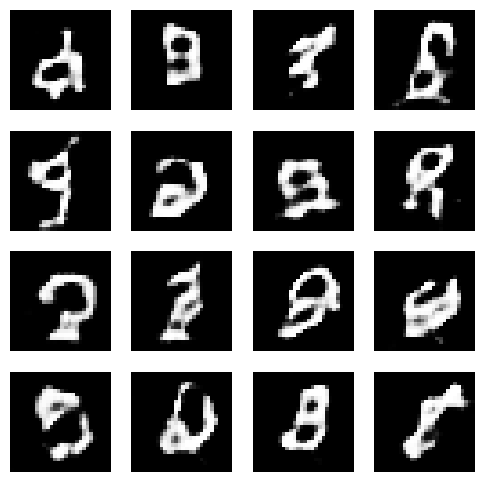

Epoch: 6 Generator Loss: 0.8554 Discriminator Loss: 1.2562


In [ ]:
# EXPT NO: 8
# NAME: Lathika M
# REGISTER NO: 24BAD062
# PART C: GAN TRAINING

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

print("Name: Lathika M")
print("Register Number: 24BAD062")
print("GAN Training Started")

# Loss function
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

# Optimizers
generator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

discriminator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

# Training parameters
EPOCHS = 30
LATENT_DIM = 100

# Loss lists
generator_losses = []
discriminator_losses = []


# Training function
@tf.function
def train_step(real_images):

    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal([batch_size, LATENT_DIM])

    # Train Discriminator
    with tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)

        fake_output = discriminator(
            tf.stop_gradient(fake_images),
            training=True
        )

        real_loss = cross_entropy(
            tf.ones_like(real_output), real_output
        )

        fake_loss = cross_entropy(
            tf.zeros_like(fake_output), fake_output
        )

        disc_loss = real_loss + fake_loss

    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    # Train Generator
    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as gen_tape:

        generated_images = generator(noise, training=True)

        predictions = discriminator(
            generated_images, training=True
        )

        gen_loss = cross_entropy(
            tf.ones_like(predictions), predictions
        )

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    return gen_loss, disc_loss


# Display generated images
def show_images():

    noise = tf.random.normal([16, LATENT_DIM])

    images = generator(noise, training=False)

    plt.figure(figsize=(6, 6))

    for i in range(16):
        plt.subplot(4, 4, i + 1)

        plt.imshow(
            (images[i, :, :, 0] + 1) / 2,
            cmap='gray'
        )

        plt.axis('off')

    plt.show()


# Training loop
for epoch in range(EPOCHS):

    g_loss_list = []
    d_loss_list = []

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        g_loss_list.append(float(g_loss))
        d_loss_list.append(float(d_loss))

    avg_g_loss = np.mean(g_loss_list)
    avg_d_loss = np.mean(d_loss_list)

    generator_losses.append(avg_g_loss)
    discriminator_losses.append(avg_d_loss)

    print(
        "Epoch:", epoch + 1,
        "Generator Loss:", round(avg_g_loss, 4),
        "Discriminator Loss:", round(avg_d_loss, 4)
    )

    if (epoch + 1) % 5 == 0:
        print("Generated Images at Epoch:", epoch + 1)
        show_images()


print("GAN Training Completed Successfully")

# Plot Generator and Discriminator Loss
plt.figure(figsize=(8, 5))

plt.plot(generator_losses, label='Generator Loss')
plt.plot(discriminator_losses, label='Discriminator Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("GAN Training Loss")

plt.legend()
plt.grid()
plt.show()

# PART D: DIMENSIONALITY REDUCTION, FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT

In [ ]:
# EXPT NO: 8
# NAME: Lathika M
# REGISTER NO: 24BAD062
# PART D: IMAGE GENERATION AND VISUALIZATION

import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

print("Name: Lathika M")
print("Register Number: 24BAD062")
print("Synthetic Image Generation and Visualization")

# Generate random latent vectors
noise = tf.random.normal([10, LATENT_DIM])

# Generate synthetic images
synthetic_images = generator(noise, training=False)

print("Synthetic Images Generated")
print("Generated Image Shape:", synthetic_images.shape)

# Display original images
plt.figure(figsize=(12, 4))
plt.suptitle("Original MNIST Images")

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i, :, :, 0], cmap='gray')
    plt.axis('off')

plt.show()

# Display generated images
plt.figure(figsize=(12, 4))
plt.suptitle("GAN Generated Synthetic Images")

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = (synthetic_images[i, :, :, 0] + 1) / 2

    plt.imshow(image, cmap='gray')
    plt.axis('off')

plt.show()

# Display latent space representation
print("Latent Space Representation")
print(noise.numpy()[:2])

# Save Generator model
generator.save("GAN_Generator.keras")

print("Generator Model Saved Successfully")

print("Image Comparison Completed")
print("Name: Lathika M")
print("Register Number: 24BAD062")